*Notebook 02 in `notebooks/arcs/`. Parameters (pre-registered): `analysis/arcs/config.yaml`; decisions and run notes: `analysis/arcs/LOG.md`. The static page `site/arcs/index.html` is built from the same saved outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/arcs -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.scripts_text.report import nb_md
from analysis.static_figures import use_static_figures

from analysis.arcs import s02_units as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 2 · Text units: scenes and sentences

How do we turn a screenplay file into an ordered list of scenes, each with sentences we can score?

We cut each screenplay into its `<scene>` blocks, in the order they appear, and split each scene into two
layers:
- **dialogue**: what characters say, from the `<dialogue>` tags
- **action**: what the script describes happening, from the `<scene_description>` tags.

The two together, **both**, are the primary layer. We don't score scene headings ("INT. KITCHEN - NIGHT"),
speaker names or parentheticals, because they carry places and names, not tone.

Inside each tag we split the text into sentences after `.`, `!` or `?`. A tag boundary is always a sentence
boundary. Later we compute sentiment **per sentence** and average it per scene.

### Fixing split contractions first
Some MovieSum scripts are pre-tokenised, so "don't" appears as "do n't". We expected this to break negation in
a lexicon. VADER's negation check does catch a split "n't" on its own, but Step 3 measured every affected sentence
and joining still changes about 1.4% of the VADER scores it touches, so the fix matters for VADER too. The fix still matters for word
counts (otherwise "n't", "ca" and "wo" count as words) and for a contextual model, whose tokenizer would see an
unusual sequence. Pre-tokenised and ordinary scripts now go through the same processing.

### Why the scene is the unit of time
- A scene is the screenwriter's own unit of story: one place, one stretch of time.
- Counting by pages or words would give long description passages more weight than quick exchanges.
- Counting by speeches would give talky scenes more weight than action scenes.

### Assumption
The scene order in the file is the story order. Only a handful of scripts number their scenes, so we can't
check it.

### What it misses
- Scenes differ in length, so a short scene's mean rests on few sentences and is noisy (Step 5 checks this).
- A scene with only a heading has no sentences and drops out of the timeline. We count these scenes rather
  than hide them.
- Splitting on punctuation misses sentences that have no end punctuation and splits at "Mr.". That only
  changes how finely a scene is cut, not what it says.

> **Takeaway.** 834 non-franchise scripts are long enough and well enough marked up to build an arc. The median one has 133 scenes and 21.0 sentences per scene. We assume the scene order in the file is the story order, because only 3 scripts number most of their scenes.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Table.** Parser sanity report over the 1,087 scripts left after Step 1's exclusions.

In [3]:
display(step.tables(res)["sanity"])

,check,count,note
0,scripts parsed,1087,
1,parse errors,0,
2,scene tags in all scripts,148637,
3,scenes with no dialogue or action sentence (dropped from the timeline),456,mostly a heading or a speaker cue alone
4,"sentences, dialogue",1675413,
5,"sentences, action",1474316,
6,split contractions joined,155109,"""do n't"" → ""don't"""
7,pre-tokenised scripts (≥ 20 joins),471,fix applied to every script anyway
8,possible transcripts (action share < 0.15 or < 20 scene tags),55,"9 of them in the primary sample; flagged, kept"
9,scripts whose headings are mostly numbered,3,the rest give no scene numbers: order of appearance is the timeline


**Table.** Before and after the contraction fix, counted over every script, with a made-up example so no script text is needed.

In [4]:
display(step.tables(res)["contractions"])

,what,before the fix,after the fix
0,"standalone ""n't"" tokens (a negation cut off from its verb)",73083,1
1,"example (constructed, not from a script)",I do n't love you .,I don't love you .
2,does it change a VADER score?,"no, on the hand-made cases: VADER's negation check matches any token containing ""n't"", so a split ""n't"" still negates",measured on every affected sentence in Step 3
3,why we fix it anyway,"""n't"" is counted as a word; ""ca"", ""wo"" appear as words; a contextual model sees an unusual token sequence",word counts and tokenisation are the same for pre-tokenised and ordinary scripts


**Private check.** five real before/after negation cases, at most 15 words each (notebook only).

In [5]:
display(step.private(res)["negation"])   # output cleared before commit

**Table.** Before and after for three example scripts, as counts only: what the markup holds and what becomes a scored unit. Headings, speaker cues and parentheticals stay out of the score.

In [6]:
display(step.tables(res)["examples"])

,film,scene tags,headings (not scored),dialogue tags,description tags,cues + parentheticals (not scored),scenes kept on the timeline,dialogue sentences,action sentences,mean sentences / scene,split contractions joined
0,Pulp Fiction_1994,85,85,1341,432,1494,85,2209,1127,39.2,508
1,Inception_2010,285,284,1271,764,1329,285,1973,1586,12.5,0
2,The Godfather_1972,225,225,946,554,1108,225,1742,1574,14.7,299


**Figure.** Each mark is a non-franchise script: scene tags (x) against dialogue + action sentences (y), both on log scales. The dashed lines are the arc-ready filter we fixed in advance. Excluded scripts (orange crosses) sit left of or below the lines, because their scene markup is missing or they're too short for a 100-point arc.

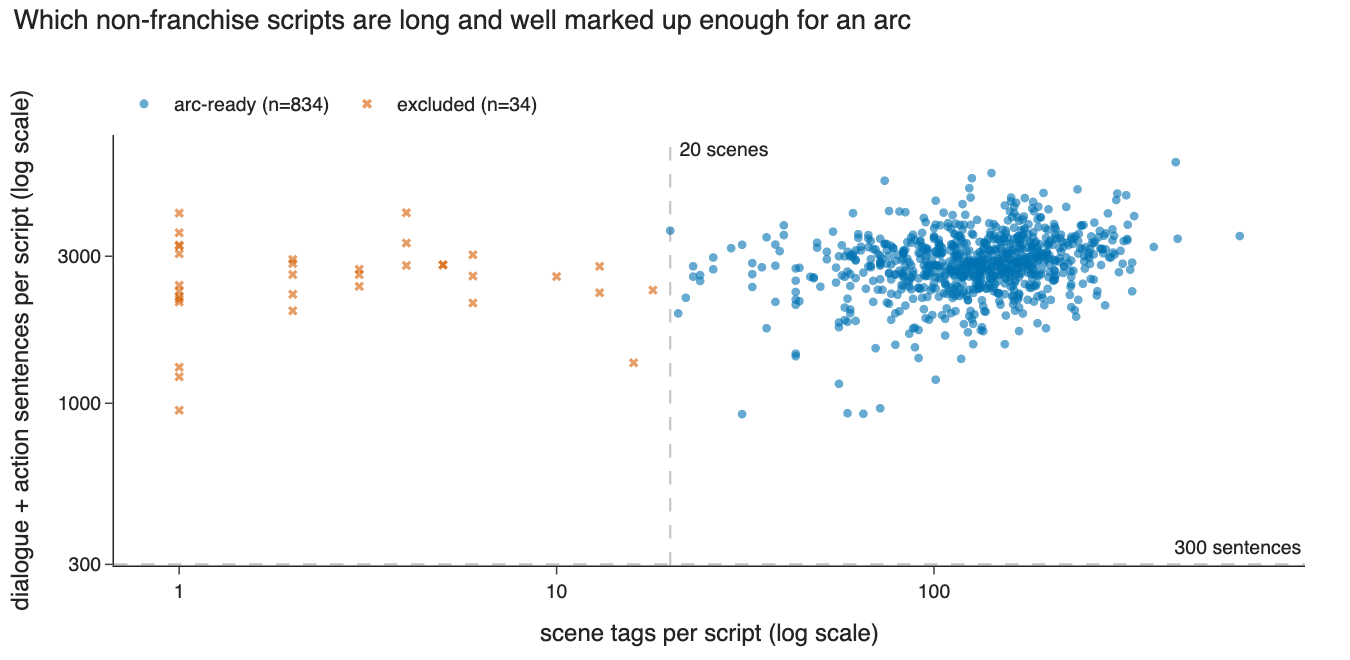

In [7]:
step.figures(res)["arc_ready"].show()

**Table.** The funnel continued from Step 1: the arc-ready filter, a stricter and a looser version of it for sensitivity checks, and the all-scripts sample used in Steps 9 and 10.

In [8]:
display(step.tables(res)["funnel"])

,stage,films,note
0,not likely franchise (Step 1),868,
1,… with fewer than 20 scene tags,-34,scene markup missing: the film would read as a handful of scenes
2,… with enough scenes but fewer than 300 sentences,0,too little text for a 100-point arc
3,"PRIMARY SAMPLE: arc-ready, not likely franchise",834,expected 834
4,"sensitivity: strict filter (≥ 40 scenes, ≥ 600 sentences)",812,
5,"sensitivity: loose filter (≥ 10 scenes, ≥ 150 sentences)",839,
6,"all scripts, arc-ready (franchise included)",1043,sensitivity sample


**Table.** Size of each script in the primary sample: 10th, 50th and 90th percentiles.

In [9]:
display(step.tables(res)["describe"])

,per script (primary sample),count,mean,std,min,10%,50%,90%,max
0,n_scene_tags,834.0,141.92,65.98,20.00,67.30,133.00,226.40,646.00
1,scenes_nonempty_both,834.0,141.49,65.66,16.00,67.00,133.00,224.70,633.00
2,sentences_both,834.0,2891.80,630.78,922.00,2166.00,2859.50,3619.70,6060.00
3,sentences_dialogue,834.0,1557.93,488.42,90.00,1012.00,1515.00,2147.10,4618.00
4,sentences_action,834.0,1333.87,487.79,0.00,768.60,1297.50,1964.40,3424.00
5,mean_sentences_per_scene,834.0,25.59,17.14,5.51,12.65,21.02,41.66,227.06
6,action_share,834.0,0.55,0.14,0.00,0.38,0.57,0.72,0.98


**Figure.** Mean sentences per scene for each primary script. This is the 'scene length' control. A script made of short scenes gets noisier scene scores, which could inflate volatility (D1).

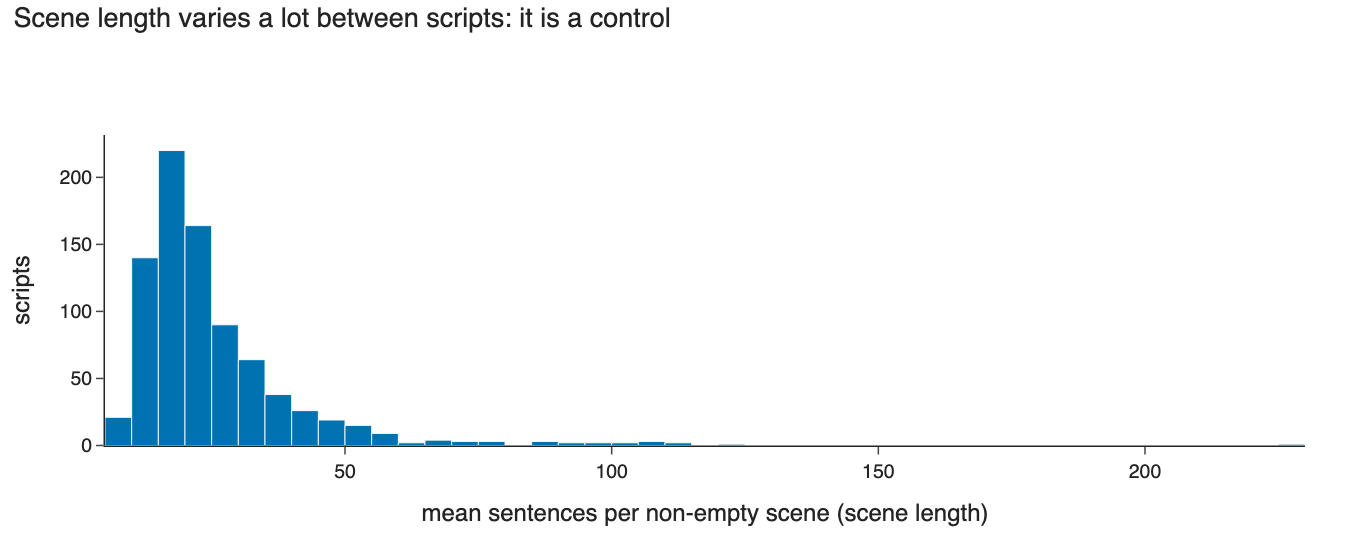

In [10]:
step.figures(res)["scene_length"].show()

**Figure.** Number of sentences in a single scene, over all scenes of the primary scripts. Many scenes have only a few sentences, which is why scene scores are noisy and we smooth the arc.

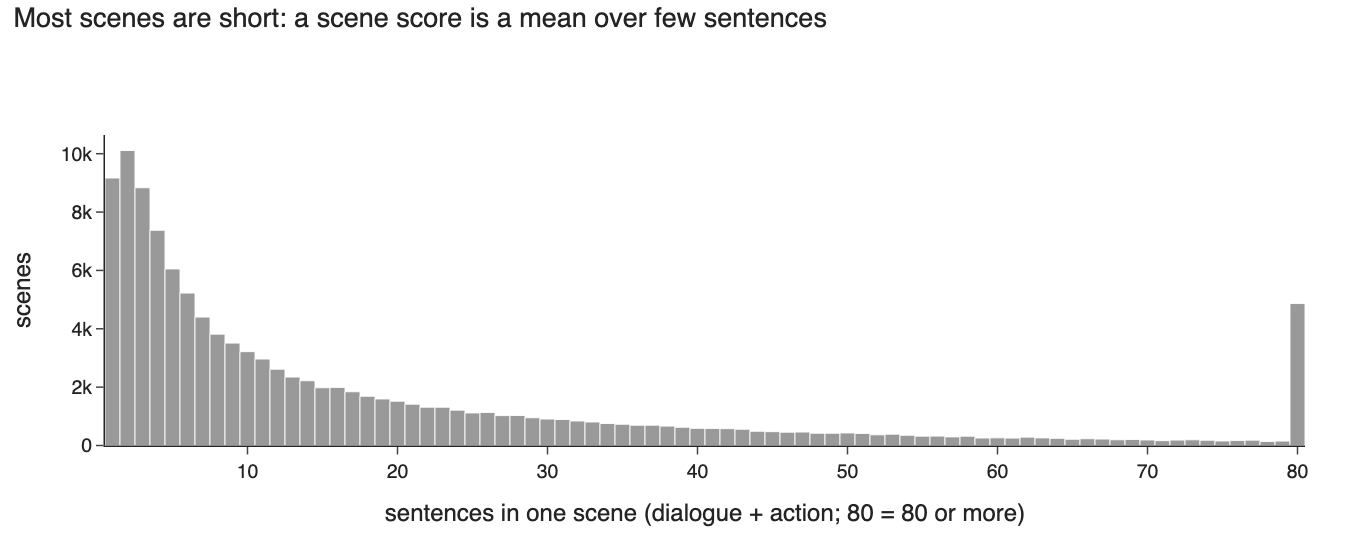

In [11]:
step.figures(res)["sentences_per_scene"].show()

**Plain-language reading** (generated from the saved numbers):

In [12]:
display(Markdown(nb_md(step.reading(res))))

All 1,087 scripts parse (0 errors). Together they hold 148,637 scene tags, and 456 of those scenes have no dialogue or description sentence, so they drop out of the timeline. Joining 155,109 split contractions cut the standalone "n't" tokens from 73,083 to 1. 471 scripts are pre-tokenised (≥ 20 joins). 834 non-franchise scripts are arc-ready (we expected 834). The median one has 133 scenes, 2,860 sentences and 21.0 sentences per scene, with 57% of its words in descriptions. 9 possible transcripts remain in the primary sample. They're flagged, and Step 10 drops them. Only 3 scripts number most of their scene headings. So for nearly all scripts we take the order in which scenes appear in the file to be the story order, and we can't check that assumption from the markup.